<a href="https://colab.research.google.com/github/sinbbang/L-IntelligentSystem/blob/main/%EC%A7%80%EB%8A%A5%EC%8B%9C%EC%8A%A4%ED%85%9C_10-3_Single_vs_Multi_Agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 실습 3. Single-Agent vs Multi-Agent 성능 비교

### 학습 목표
1. 동일한 여행 계획 문제를 **Single(순차)**, **Single(비동기 도구)**, **Multi(병렬 Worker)** 방식으로 처리한다.
2. **실행 시간 / 모의 토큰 예산 / 조건 충족 개수**를 공정하게 비교한다.
3. Multi-Agent의 성능 향상과 **병렬 실행의 효과**를 구분해 설명한다.

> **주의:** 이 노트북은 실제 LLM/API를 사용하지 않는 **구조 학습용 시뮬레이션**입니다. 실행 시간은 `asyncio.sleep()` 대기 시간으로 만든 값이며, 토큰은 교육용 가정값입니다. **실제 AI의 정확도·토큰·비용을 측정한 결과가 아닙니다.** 관광지·식당·교통 정보도 예제이며 실제 여행 정보를 보증하지 않습니다.

**실행법:** Colab에서 노트북을 열고 `런타임 → 모두 실행`을 누르세요. 파일 업로드, API 키, 추가 패키지가 필요하지 않습니다.

## 1. 준비: 동일한 입력과 실습 데이터
실습 2의 부산 당일치기 여행 문제를 그대로 사용합니다. **세 실행 방식 모두 동일한 데이터, 동일한 규칙, 동일한 도구**를 사용합니다.

In [1]:
# asyncio: 비동기 대기를 이용해 여러 작업을 동시에 예약합니다.
import asyncio
# json: 실습 데이터를 JSON 파일로 저장하고 다시 읽습니다.
import json
# statistics: 여러 번 실행한 시간의 평균을 계산합니다.
import statistics
# time: 각 방식의 경과 시간을 측정합니다.
import time
# pathlib: Colab의 현재 작업 폴더에 데이터를 저장합니다.
from pathlib import Path

# 세 방식 모두 사용할 공통 데이터 파일 이름입니다.
DATA_PATH = Path('busan_trip_lab3.json')

# 실제 영업 여부/요금이 아닌 가상의 교육용 값입니다.
EXAMPLE_DATA = {
    'attractions': [
        {'name': '해운대 해수욕장', 'area': '해운대', 'duration_min': 70, 'estimated_cost': 0},
        {'name': '광안리 해수욕장', 'area': '광안리', 'duration_min': 70, 'estimated_cost': 0},
    ],
    'restaurants': [
        {'name': '해운대 식당 A (가상)', 'area': '해운대', 'menu': '돼지국밥', 'estimated_cost': 12000},
        {'name': '광안리 식당 B (가상)', 'area': '광안리', 'menu': '밀면', 'estimated_cost': 11000},
    ],
    'transport': [
        {'from': '부산역', 'to': '해운대', 'method': '대중교통', 'estimated_min': 60},
        {'from': '해운대', 'to': '광안리', 'method': '대중교통', 'estimated_min': 40},
        {'from': '광안리', 'to': '부산역', 'method': '대중교통', 'estimated_min': 50},
    ],
}

# JSON 파일을 만들어 자료 조회 과정을 재현합니다.
DATA_PATH.write_text(json.dumps(EXAMPLE_DATA, ensure_ascii=False, indent=2), encoding='utf-8')

# 세 방식에 모두 전달할 동일한 사용자 요청입니다.
REQUEST = {'city': '부산', 'party_size': 4, 'budget_per_person': 15000,
           'must_visit': ['해운대', '광안리'], 'trip_type': '당일치기'}

print('준비 완료:', DATA_PATH.name, '/ 여행 인원:', REQUEST['party_size'], '명')

준비 완료: busan_trip_lab3.json / 여행 인원: 4 명


## 2. 공통 도구 세 개: 관광지 / 음식점 / 교통 조회
각 함수는 **같은 자료에서 같은 규칙으로** 결과를 만듭니다. `await asyncio.sleep(...)`은 웹 검색/API 응답을 기다리는 상황을 **가상으로 모의**합니다.

In [2]:
# 각 도구의 대기 시간(초)입니다. 숫자를 바꿔 실험할 수 있습니다.
TOOL_DELAY = {'attractions': 0.18, 'restaurants': 0.24, 'transport': 0.15}

# 이 리스트는 누가 언제 시작/종료했는지 남기는 간단한 실행 로그입니다.
TRACE = []

def log(agent: str, event: str):
    """실행 시작·종료 시각을 기록합니다."""
    # perf_counter()는 경과 시간 비교에 적합한 시계입니다.
    TRACE.append({'time': time.perf_counter(), 'agent': agent, 'event': event})

async def query_tool(category: str, request: dict, agent: str) -> dict:
    """실습용 데이터를 읽는 도구를 실행하고 결과를 구조화해 반환합니다."""
    # 작업이 시작됐음을 기록합니다.
    log(agent, f'{category}: 시작')
    # 외부 API의 응답 대기 시간을 흉내 냅니다(실제 네트워크 요청 없음).
    await asyncio.sleep(TOOL_DELAY[category])
    # 모든 방식이 동일한 파일에서 자료를 읽습니다.
    database = json.loads(DATA_PATH.read_text(encoding='utf-8'))
    items = database[category]
    if category == 'restaurants':
        # 식당은 사용자의 1인당 예산을 넘지 않는 후보만 남깁니다.
        items = [x for x in items if x['estimated_cost'] <= request['budget_per_person']]
    elif category == 'attractions':
        # 관광지는 사용자가 요청한 지역에 속하는 장소만 남깁니다.
        items = [x for x in items if x['area'] in request['must_visit']]
    # 누가 어떤 자료를 반환했는지 추적 가능하도록 작성합니다.
    result = {'worker': category, 'status': 'success', 'items': items,
              'source': DATA_PATH.name}
    log(agent, f'{category}: 종료')
    return result

print('공통 도구:', ', '.join(TOOL_DELAY.keys()))

공통 도구: attractions, restaurants, transport


## 3. 공통 검증과 여행 일정 생성
**평가의 공정성**을 위해 결과를 검증하고 일정표로 바꾸는 함수도 세 방식에서 똑같이 사용합니다.

In [3]:
def validate_result(result: dict, expected_category: str):
    """작업명, 결과 형태, 자료 출처가 올바른지 확인합니다."""
    # 결과 형식이 잘못된 경우 조용히 넘어가지 않고 오류를 알립니다.
    if not isinstance(result, dict):
        raise ValueError('도구 결과가 딕셔너리가 아닙니다.')
    if result.get('worker') != expected_category or result.get('status') != 'success':
        raise ValueError(f'{expected_category}: 작업명 또는 상태 오류')
    if not isinstance(result.get('items'), list) or not result['items']:
        raise ValueError(f'{expected_category}: 검색 결과가 없습니다.')
    if result.get('source') != DATA_PATH.name:
        raise ValueError('출처 파일이 일치하지 않습니다.')

def build_plan(request: dict, results: list[dict]) -> dict:
    """세 도구의 반환값을 검증하고 공통 규칙으로 하나의 일정표로 만듭니다."""
    # 함수 호출 순서가 달라도 category를 기준으로 결과를 찾습니다.
    lookup = {result['worker']: result for result in results}
    for category in TOOL_DELAY:
        validate_result(lookup[category], category)

    # 방문지와 점심 장소는 같은 기준으로 선택합니다.
    beaches = lookup['attractions']['items']
    restaurants = lookup['restaurants']['items']
    routes = lookup['transport']['items']
    haeundae = next(x for x in beaches if x['area'] == '해운대')
    gwangalli = next(x for x in beaches if x['area'] == '광안리')
    lunch = next(x for x in restaurants if x['area'] == '해운대')

    # 실제 출발/도착 시각이 아니라 순서와 예시 소요 분만 작성합니다.
    itinerary = [
        {'kind': '교통', 'name': '부산역 → 해운대', 'minutes': routes[0]['estimated_min']},
        {'kind': '관광', 'name': haeundae['name'], 'minutes': haeundae['duration_min']},
        {'kind': '식사', 'name': lunch['name'], 'minutes': 60},
        {'kind': '교통', 'name': '해운대 → 광안리', 'minutes': routes[1]['estimated_min']},
        {'kind': '관광', 'name': gwangalli['name'], 'minutes': gwangalli['duration_min']},
        {'kind': '교통', 'name': '광안리 → 부산역', 'minutes': routes[2]['estimated_min']},
    ]
    # 미확인 교통비·간식비가 있어 총 여행 경비라고 해석하면 안 됩니다.
    return {'city': request['city'], 'party_size': request['party_size'],
            'itinerary': itinerary, 'sample_meal_cost_per_person': lunch['estimated_cost'],
            'sources': sorted({result['source'] for result in results}),
            'missing_costs': ['교통비', '간식비'],
            'notice': '가상 예제입니다. 실제 운행 시간과 영업 여부는 확인하지 않았습니다.'}

print('공통 결과 검증·통합 함수 준비 완료')

공통 결과 검증·통합 함수 준비 완료


## 4. 세 가지 실행 방식 구현
- **A. Single(순차):** 에이전트 한 개가 도구를 하나씩 호출합니다.
- **B. Single(비동기 도구):** 에이전트는 한 개이지만 독립적인 도구 호출을 동시에 기다립니다.
- **C. Multi(병렬 Worker):** 지휘자가 세 Worker에게 일을 맡기고 결과를 합칩니다.

> **중요한 반론:** 병렬 실행은 Multi-Agent만의 장점이 아닙니다. 단일 에이전트도 병렬 도구 호출을 할 수 있으므로 B 기준선이 반드시 필요합니다.

In [4]:
# 여러 Agent를 조율할 때의 추가 지연을 가정합니다. 실제 측정값이 아닙니다.
COORDINATION_DELAY = 0.07

async def single_sequential(request: dict) -> dict:
    """Single Agent가 도구 3개를 차례대로 사용하는 방식입니다."""
    # 도구 호출마다 바로 await하므로 이전 호출이 끝나야 다음 호출을 진행합니다.
    results = []
    for category in TOOL_DELAY:
        results.append(await query_tool(category, request, 'Single Agent'))
    return build_plan(request, results)

async def single_parallel_tools(request: dict) -> dict:
    """한 Agent가 독립적인 도구 세 개를 비동기로 호출하는 방식입니다."""
    # Agent 수는 하나이며, 동시에 실행하는 것은 '도구 요청'입니다.
    calls = [query_tool(category, request, 'Single Agent') for category in TOOL_DELAY]
    results = await asyncio.gather(*calls)
    return build_plan(request, results)

async def multi_parallel_workers(request: dict) -> dict:
    """Orchestrator가 세 Worker를 병렬 실행하고 결과를 검증·통합합니다."""
    log('Orchestrator', '작업 분배')
    # Worker마다 맡는 자료 종류가 다르며 서로의 결과를 기다리지 않습니다.
    async def worker(category: str) -> dict:
        # Worker의 작업을 query_tool에 위임합니다.
        return await query_tool(category, request, f'Worker-{category}')
    results = await asyncio.gather(*(worker(category) for category in TOOL_DELAY))
    # 작업 분배·결과 확인·조율에 드는 추가 대기 시간을 모의합니다.
    await asyncio.sleep(COORDINATION_DELAY)
    log('Orchestrator', '결과 통합')
    return build_plan(request, results)

MODES = {
    'Single 순차': single_sequential,
    'Single 병렬 도구': single_parallel_tools,
    'Multi 병렬 Worker': multi_parallel_workers,
}
print('비교 대상:', ' / '.join(MODES))

비교 대상: Single 순차 / Single 병렬 도구 / Multi 병렬 Worker


## 5. 평가 기준 정의: 실행 시간·품질·모의 토큰
품질 점수(5점 만점)는 사전에 정한 다섯 조건의 충족 여부를 검사합니다. 토큰 수는 실제 토크나이저 결과가 아니라 **가상의 예산 표**입니다.

In [5]:
def quality_checks(plan: dict, request: dict) -> dict:
    """여행 계획이 지켜야 할 다섯 가지 조건을 자동 검사합니다."""
    steps = plan.get('itinerary', [])
    names = ' / '.join(step.get('name', '') for step in steps)
    # 학생들이 직접 요구조건을 바꾸면서 평가 결과를 관찰할 수 있습니다.
    return {
        '4명 일정': plan.get('party_size') == request['party_size'],
        '해운대 방문': '해운대 해수욕장' in names,
        '광안리 방문': '광안리 해수욕장' in names,
        '식사 예산 준수': plan.get('sample_meal_cost_per_person', 10**9) <= request['budget_per_person'],
        '자료 출처 포함': DATA_PATH.name in plan.get('sources', []),
    }

# 아래 값은 대화/출력에 소요되는 토큰을 임의로 가정한 것입니다.
# 실제 LLM 호출 또는 토크나이저 계산이 아니며, 비용 비교 '개념' 설명에 사용합니다.
SIMULATED_TOKENS = {
    'Single 순차': {'입력·지시': 300, '도구 결과': 360, '최종 답변': 280, '조율': 0},
    'Single 병렬 도구': {'입력·지시': 300, '도구 결과': 360, '최종 답변': 280, '조율': 0},
    'Multi 병렬 Worker': {'입력·지시': 450, '도구 결과': 360, '최종 답변': 280, '조율': 240},
}

def simulated_token_total(mode: str) -> int:
    """사용자가 설정한 모의 토큰 항목의 합계를 계산합니다."""
    return sum(SIMULATED_TOKENS[mode].values())

for name in MODES:
    print(f'{name}: 모의 토큰 {simulated_token_total(name):,}개')

Single 순차: 모의 토큰 940개
Single 병렬 도구: 모의 토큰 940개
Multi 병렬 Worker: 모의 토큰 1,330개


## 6. 동일 조건으로 반복 실행
시간 측정은 가벼운 흔들림이 있으므로 각 방식을 **3회 반복**한 뒤 평균을 계산합니다. 평가 결과와 실행 로그도 함께 저장합니다.

In [6]:
# 반복 횟수입니다. 수업 시간이 충분하면 5 또는 10으로 높여 보세요.
REPEATS = 3
# 모든 방식의 평가 결과를 저장할 목록입니다.
RESULTS = []
# 이후에 실행 경로를 살펴볼 수 있도록 모드별 마지막 Trace를 보관합니다.
LAST_TRACES = {}
# 모드별 마지막 여행 계획을 보관합니다.
LAST_PLANS = {}

for mode_name, run_function in MODES.items():
    runtimes = []
    for trial in range(REPEATS):
        TRACE.clear()  # 이전 시도 기록과 섞이지 않도록 로그를 비웁니다.
        started = time.perf_counter()
        plan = await run_function(REQUEST)
        elapsed = time.perf_counter() - started
        runtimes.append(elapsed)
        # 같은 방식에서 마지막 시험의 로그와 계획만 저장합니다.
        LAST_TRACES[mode_name] = [entry.copy() for entry in TRACE]
        LAST_PLANS[mode_name] = plan
    # 5개 기준에 따른 점수를 계산합니다.
    checks = quality_checks(LAST_PLANS[mode_name], REQUEST)
    RESULTS.append({'방식': mode_name,
                    '평균 실행 시간(초)': statistics.mean(runtimes),
                    '모의 토큰(개)': simulated_token_total(mode_name),
                    '품질 점수(5점)': sum(checks.values()),
                    '반복 시간': runtimes})
    print(f'{mode_name:18s} | 시간 {statistics.mean(runtimes):.3f}초'
          f' | 모의 토큰 {simulated_token_total(mode_name):,}개'
          f' | 조건 충족 {sum(checks.values())}/5')

print('\n※ 시간은 모의 I/O 대기, 토큰은 입력한 가정값, 품질은 규칙 검사 결과입니다.')

Single 순차          | 시간 0.573초 | 모의 토큰 940개 | 조건 충족 5/5
Single 병렬 도구       | 시간 0.242초 | 모의 토큰 940개 | 조건 충족 5/5
Multi 병렬 Worker    | 시간 0.314초 | 모의 토큰 1,330개 | 조건 충족 5/5

※ 시간은 모의 I/O 대기, 토큰은 입력한 가정값, 품질은 규칙 검사 결과입니다.


## 7. 시간과 토큰을 나란히 비교
표는 정확한 수치를 보여 주고, 두 그래프는 시간·모의 토큰의 차이를 각각 보여 줍니다. **서로 단위가 달라 한 축에 섞지 않습니다.**

In [7]:
# 비교 결과를 복사하기 쉽게 표 형태로 출력합니다.
print(f'{"구조":<21} {"평균 시간(초)":>14} {"모의 토큰":>12} {"조건 충족":>10}')
print('-' * 65)
for row in RESULTS:
    print(f'{row["방식"]:<21} {row["평균 실행 시간(초)"]:>14.3f} '
          f'{row["모의 토큰(개)"]:>12,d} {row["품질 점수(5점)"]:>9}/5')

# 기준선을 명확히 표시합니다. Multi가 Single 병렬 도구보다 빠른지 확인하세요.
by_name = {r['방식']: r for r in RESULTS}
seq_t = by_name['Single 순차']['평균 실행 시간(초)']
single_parallel_t = by_name['Single 병렬 도구']['평균 실행 시간(초)']
multi_t = by_name['Multi 병렬 Worker']['평균 실행 시간(초)']
print(f'\nSingle 순차 대비 Multi 속도 비율: {seq_t / multi_t:.2f}배')
print(f'Single 병렬 도구 대비 Multi 속도 비율: {single_parallel_t / multi_t:.2f}배')

구조                          평균 시간(초)        모의 토큰      조건 충족
-----------------------------------------------------------------
Single 순차                      0.573          940         5/5
Single 병렬 도구                   0.242          940         5/5
Multi 병렬 Worker                0.314        1,330         5/5

Single 순차 대비 Multi 속도 비율: 1.83배
Single 병렬 도구 대비 Multi 속도 비율: 0.77배


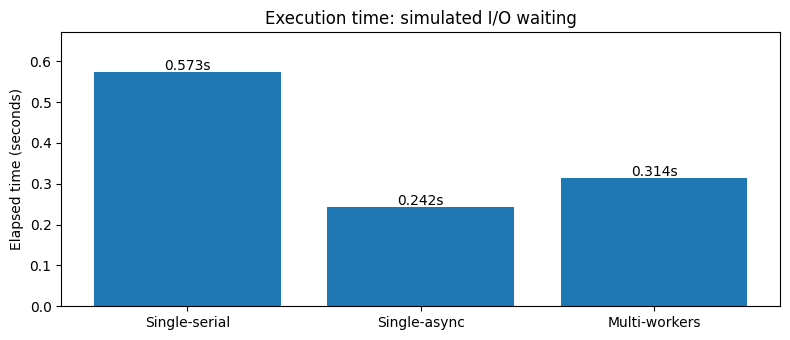

In [8]:
# matplotlib은 Colab에 기본 설치된 그래프 라이브러리입니다.
import matplotlib.pyplot as plt

# 한글 글꼴 설치 없이도 읽기 쉽도록 영문 짧은 레이블로 표시합니다.
labels = ['Single-serial', 'Single-async', 'Multi-workers']
times = [row['평균 실행 시간(초)'] for row in RESULTS]

# 첫 번째 차트: 실제 측정한 경과 시간을 보여 줍니다(모의 I/O 대기 기반).
plt.figure(figsize=(8, 3.5))
plt.bar(labels, times)
plt.ylabel('Elapsed time (seconds)')
plt.title('Execution time: simulated I/O waiting')
for i, value in enumerate(times):
    plt.text(i, value + 0.006, f'{value:.3f}s', ha='center')
plt.ylim(0, max(times) * 1.17)
plt.tight_layout()
plt.show()

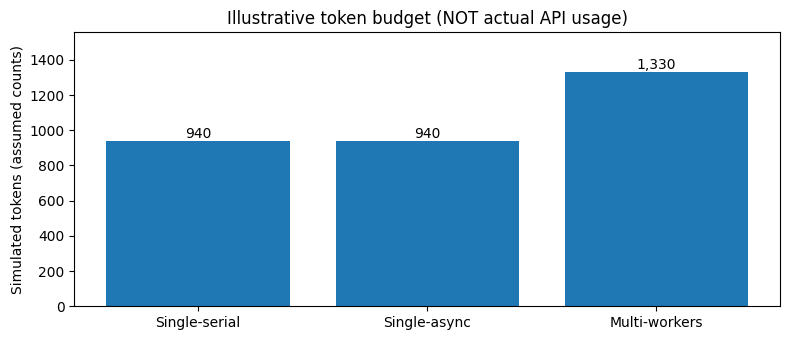

In [9]:
# 두 번째 차트: 실제 토큰 측정값이 아닌 교육용 '가정 예산'입니다.
counts = [row['모의 토큰(개)'] for row in RESULTS]
plt.figure(figsize=(8, 3.5))
plt.bar(labels, counts)
plt.ylabel('Simulated tokens (assumed counts)')
plt.title('Illustrative token budget (NOT actual API usage)')
for i, value in enumerate(counts):
    plt.text(i, value + 18, f'{value:,}', ha='center')
plt.ylim(0, max(counts) * 1.17)
plt.tight_layout()
plt.show()

## 8. Trace 확인: 작업이 겹쳐 실행됐는가?
같은 실행에서 시작 시각과 종료 시각을 비교해 **병렬 작업의 겹침**을 확인합니다. 각 실행마다 시각의 기준점을 0으로 맞춥니다.

In [10]:
for mode_name, entries in LAST_TRACES.items():
    print(f'\n[{mode_name}]')
    # 해당 실행에서 가장 처음 기록된 시간을 0초로 설정합니다.
    origin = entries[0]['time'] if entries else 0
    # 출력은 실행 순서 그대로 표시하므로 병렬 도구가 함께 시작한 것을 볼 수 있습니다.
    for entry in entries:
        print(f' +{entry["time"]-origin:.3f}초 | '
              f'{entry["agent"]:21s} | {entry["event"]}')


[Single 순차]
 +0.000초 | Single Agent          | attractions: 시작
 +0.183초 | Single Agent          | attractions: 종료
 +0.183초 | Single Agent          | restaurants: 시작
 +0.423초 | Single Agent          | restaurants: 종료
 +0.423초 | Single Agent          | transport: 시작
 +0.575초 | Single Agent          | transport: 종료

[Single 병렬 도구]
 +0.000초 | Single Agent          | attractions: 시작
 +0.000초 | Single Agent          | restaurants: 시작
 +0.000초 | Single Agent          | transport: 시작
 +0.152초 | Single Agent          | transport: 종료
 +0.181초 | Single Agent          | attractions: 종료
 +0.244초 | Single Agent          | restaurants: 종료

[Multi 병렬 Worker]
 +0.000초 | Orchestrator          | 작업 분배
 +0.000초 | Worker-attractions    | attractions: 시작
 +0.000초 | Worker-restaurants    | restaurants: 시작
 +0.000초 | Worker-transport      | transport: 시작
 +0.152초 | Worker-transport      | transport: 종료
 +0.183초 | Worker-attractions    | attractions: 종료
 +0.243초 | Worker-restaurants    | restaurants: 종료
 +0.3

## 9. 자동 검증: 결과를 공정하게 비교했는가?
세 방식이 **동일한 계획과 동일한 품질 점수**를 반환해야 합니다. 서로 다른 결과가 나오면 실행 구조 이외의 조건이 달라졌을 수 있습니다.

In [11]:
# 실행 방식만 다르고 결과를 만드는 규칙이 동일한지 검사합니다.
assert LAST_PLANS['Single 순차'] == LAST_PLANS['Single 병렬 도구']
assert LAST_PLANS['Single 순차'] == LAST_PLANS['Multi 병렬 Worker']

# 도구가 참조하는 출처·여행 인원·예산 제약이 일치하는지 검사합니다.
for mode_name, plan in LAST_PLANS.items():
    assert DATA_PATH.name in plan['sources'], f'{mode_name}: 출처 누락'
    assert plan['party_size'] == REQUEST['party_size'], f'{mode_name}: 인원 불일치'
    assert plan['sample_meal_cost_per_person'] <= REQUEST['budget_per_person'], f'{mode_name}: 예산 초과'
    assert sum(quality_checks(plan, REQUEST).values()) == 5, f'{mode_name}: 품질 기준 미달'

print('자동 검증 통과: 세 구조의 계획·출처·5개 기준이 일치합니다.')
print('주의: 5/5점은 실제 여행 계획의 사실 정확성을 뜻하지 않습니다.')

자동 검증 통과: 세 구조의 계획·출처·5개 기준이 일치합니다.
주의: 5/5점은 실제 여행 계획의 사실 정확성을 뜻하지 않습니다.


## 10. 예제 여행 일정표 출력
세 방식이 똑같은 계획을 반환했으므로 하나의 일정만 보여 줍니다.

In [12]:
# 마지막 결과 중 하나를 꺼내 공통 계획을 출력합니다.
plan = LAST_PLANS['Single 순차']
print(f"[{plan['city']} 당일치기 / {plan['party_size']}명 / 가상 데이터]")
for number, step in enumerate(plan['itinerary'], 1):
    print(f"{number}. {step['kind']:3s} | {step['name']} ({step['minutes']}분, 예시)")
print('확인된 예시 식사비:', f"{plan['sample_meal_cost_per_person']:,}원/인")
print('미확인 비용:', ', '.join(plan['missing_costs']))
print('자료 출처:', ', '.join(plan['sources']))
print('안내:', plan['notice'])

[부산 당일치기 / 4명 / 가상 데이터]
1. 교통  | 부산역 → 해운대 (60분, 예시)
2. 관광  | 해운대 해수욕장 (70분, 예시)
3. 식사  | 해운대 식당 A (가상) (60분, 예시)
4. 교통  | 해운대 → 광안리 (40분, 예시)
5. 관광  | 광안리 해수욕장 (70분, 예시)
6. 교통  | 광안리 → 부산역 (50분, 예시)
확인된 예시 식사비: 12,000원/인
미확인 비용: 교통비, 간식비
자료 출처: busan_trip_lab3.json
안내: 가상 예제입니다. 실제 운행 시간과 영업 여부는 확인하지 않았습니다.


### 정리
- **실행 시간**은 작업을 동시에 *기다릴 수 있는지*와 조율 지연에 영향을 받습니다.
- **토큰 비용**은 실제 API가 있을 때 모델별 입력·출력 토큰을 별도로 수집해야 측정할 수 있습니다. 이 실습에서는 모의 예산만 비교합니다.
- **품질 점수**는 다섯 규칙을 확인할 뿐, 여행 정보의 사실성·추천 수준을 평가하지 않습니다.
- **최종 원칙:** Multi-Agent가 항상 좋다는 결론은 성립하지 않습니다. Single을 충분히 강한 기준선으로 만들고 **같은 과제·자원·평가 기준**에서 비교해야 합니다.